# Toeplitz-LS as a Lomb-Scargle backend (P50)
Regenerates every README figure from `data/` (no heavy compute). Heavy steps: `accuracy.py`, `timing.py`, `benchmarks/profile_pipeline.py`, `end_to_end.py` (see README → Reproduce). `data/periodograms.npz` (6 MB, gitignored) comes from `accuracy.py`; the overlay figure is skipped if it is missing.

In [1]:
import sys, pandas as pd
from pathlib import Path
from IPython.display import Image, display
HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import figures as F
D = HERE / 'data'

## Accuracy
Max/median absolute power error vs astropy's exact `cython` sum, per case. `tls` sits at ~1e-14; today's astropy `fast` at 1e-7–1e-4.

In [2]:
acc = pd.read_csv(D / 'accuracy.csv')
cols = ['star_id','mode','grid','N','Nf','astropy_fast_vs_exact_maxabs','tls_vs_exact_maxabs','tlsf_vs_exact_maxabs','tls_vs_fast_maxabs','astropy_fast_top10_same_as_exact','tls_top10_same_as_exact','tls_top10_same_as_fast']
acc[cols]

,star_id,mode,grid,N,Nf,astropy_fast_vs_exact_maxabs,tls_vs_exact_maxabs,tlsf_vs_exact_maxabs,tls_vs_fast_maxabs,astropy_fast_top10_same_as_exact,tls_top10_same_as_exact,tls_top10_same_as_fast
0,smarts-tess-v1.0-000732,assigned,lombscargle,7578,3559,4.636129e-07,1.400269e-14,2.942831e-07,4.636129e-07,True,True,True
1,smarts-tess-v1.0-000732,assigned,lombscargle_short,7578,17703,1.631522e-06,8.215650e-15,4.286925e-07,1.631522e-06,True,True,True
2,smarts-tess-v1.0-000732,fullyear,lombscargle,14706,4229,4.395131e-07,1.115774e-14,9.612376e-08,4.395131e-07,True,True,True
3,smarts-tess-v1.0-000732,fullyear,lombscargle_short,14706,21036,1.050399e-06,1.328798e-14,1.413141e-07,1.050399e-06,True,True,True
4,smarts-tess-v1.0-004513,assigned,lombscargle,2429,630,5.761335e-05,3.767819e-14,3.392072e-07,5.761335e-05,True,True,True
5,smarts-tess-v1.0-004513,assigned,lombscargle_short,2429,3137,1.003123e-04,2.760292e-14,4.046597e-07,1.003123e-04,True,True,True
6,smarts-tess-v1.0-004513,fullyear,lombscargle,13352,3931,4.852801e-06,2.272488e-14,1.099122e-07,4.852801e-06,True,True,True
7,smarts-tess-v1.0-004513,fullyear,lombscargle_short,13352,19553,1.076591e-05,5.034168e-15,1.646837e-07,1.076591e-05,True,True,True
8,smarts-tess-v1.0-017292,assigned,lombscargle,4636,1203,5.713184e-06,1.304512e-14,2.925047e-07,5.713184e-06,True,True,True
9,smarts-tess-v1.0-017292,assigned,lombscargle_short,4636,5986,2.257802e-05,6.106227e-15,3.858097e-07,2.257802e-05,True,True,True


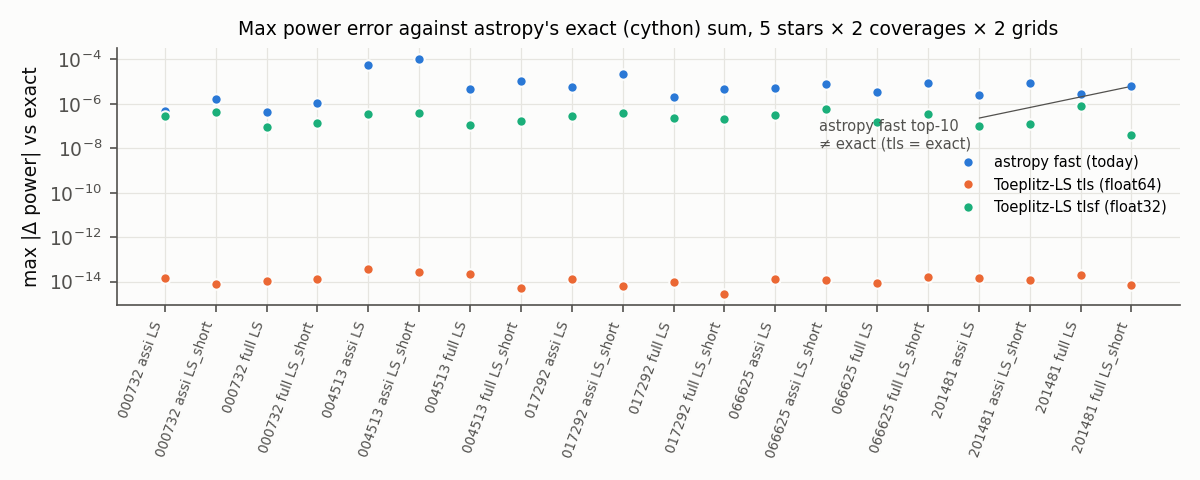

In [3]:
F.fig_error_summary(); display(Image(F.FIG / 'fig_error_summary.png'))

Periodogram overlays with residuals vs the exact sum (top-10 candidates marked).

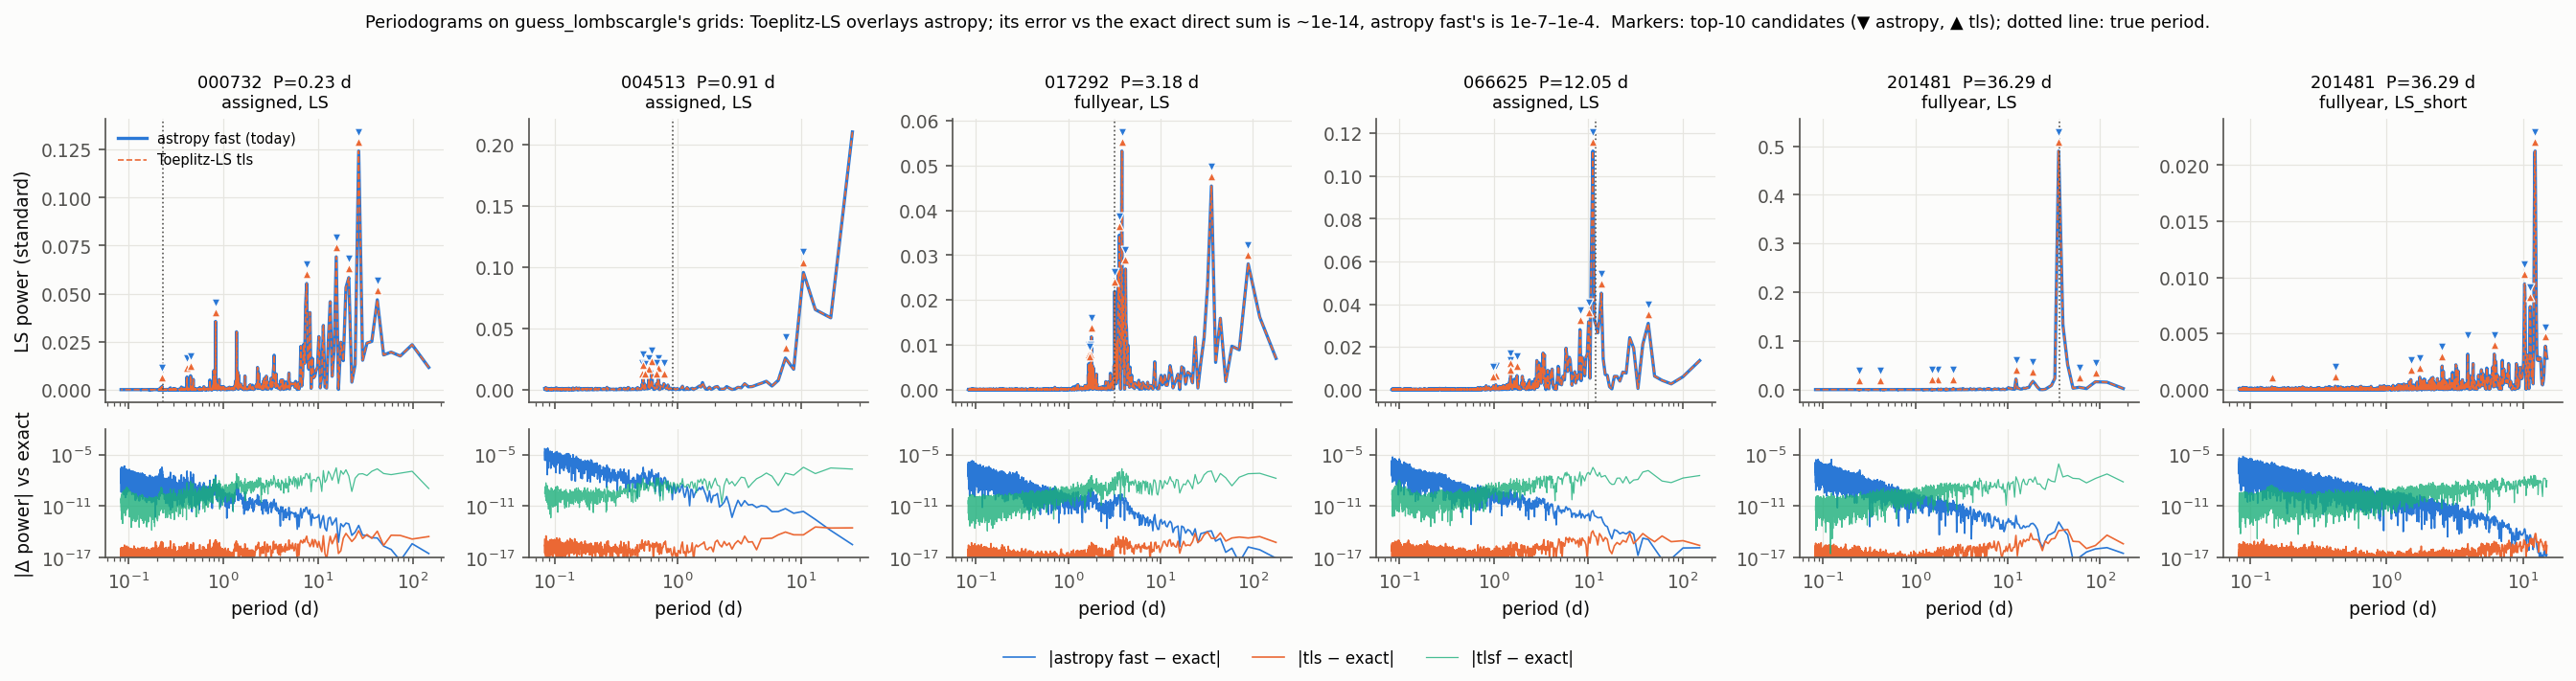

In [4]:
if (D / 'periodograms.npz').exists():
    F.fig_overlays()
display(Image(F.FIG / 'fig_periodogram_overlays.png'))

## Speed (single thread, median of 5 timeit loops)

In [5]:
tm = pd.read_csv(D / 'timing.csv'); tm['ms'] = tm.seconds * 1e3
for e in ('scan_N', 'scan_Nf', 'roman_season'):
    display(tm[tm.exp == e].pivot_table(index=['N','Nf'], columns='backend', values='ms').round(2))

,backend,astropy_fast,tls_generic,tls_native,tlsf_native
N,Nf,,,,
500,4000,3.56,1.39,0.99,0.53
1000,4000,3.20,1.88,1.18,0.73
2000,4000,5.46,2.85,1.63,1.07
5000,4000,5.60,6.38,4.59,2.07
10000,4000,7.67,11.71,8.88,3.90
20000,4000,9.89,21.78,16.07,10.13
50000,4000,19.94,51.08,39.05,23.27
100000,4000,41.44,97.61,74.93,48.46


backend       astropy_fast  tls_generic  tls_native  tlsf_native
N     Nf                                                        
14000 300             5.15        10.82        5.86         4.68
      1000            5.62        14.00       10.53         5.21
      3000            8.67        15.38       11.78         4.99
      10000          15.83        18.96       13.43         8.60
      30000          44.95        21.90       17.02        10.08
      100000         98.53        34.46       26.41        15.65
      200000        242.72        49.11       34.65        22.73

,backend,astropy_fast,tls_generic,tls_native,tlsf_native
N,Nf,,,,
8450,2111,4.78,9.52,7.76,2.94


In [6]:
r = tm[tm.exp == 'real'].pivot_table(index=['star_id','mode','grid'], columns='backend', values='ms')
for c in ('tls_generic','tls_native','tlsf_native'):
    r['speedup_' + c] = r.astropy_fast / r[c]
r.groupby(level=[1, 2])[[c for c in r if c.startswith('speedup_')]].median().round(2)

backend                     speedup_tls_generic  speedup_tls_native  \
mode     grid                                                         
assigned lombscargle                       0.70                0.92   
         lombscargle_short                 1.45                2.22   
fullyear lombscargle                       0.65                0.84   
         lombscargle_short                 1.02                1.33   

backend                     speedup_tlsf_native  
mode     grid                                    
assigned lombscargle                       1.98  
         lombscargle_short                 3.81  
fullyear lombscargle                       2.00  
         lombscargle_short                 2.22

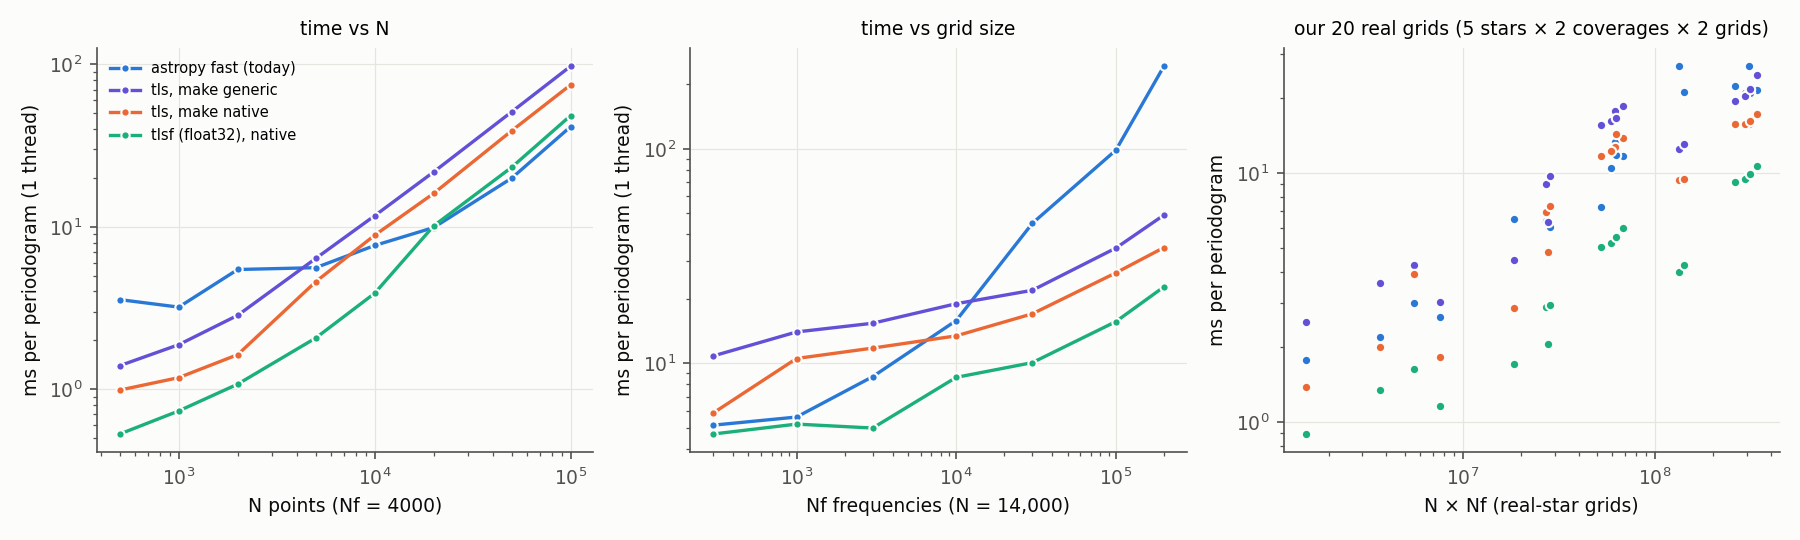

In [7]:
F.fig_timing(); display(Image(F.FIG / 'fig_timing.png'))

Run 1 of `timing.py` was flagged (another session's job appeared once during it); this compares it with the clean rerun used everywhere.

In [8]:
a = pd.read_csv(D / 'timing_run1.csv'); b = pd.read_csv(D / 'timing.csv')
k = [c for c in ['exp','N','Nf','backend','star_id','mode','grid'] if c in a]
m = a.merge(b, on=k, suffixes=('_run1', '_run2')); m['ratio'] = m.seconds_run2 / m.seconds_run1
m.ratio.describe()

count    144.000000
mean       0.991483
std        0.110305
min        0.420189
25%        0.962172
50%        0.997528
75%        1.020653
max        1.605151
Name: ratio, dtype: float64

## End-to-end share

In [9]:
pd.read_csv(D / 'end_to_end.csv')

,label,mode,path,total_ms,ls_ms,ls_share,ls_ms_tls,saved_frac_tls,ratio_tls_lombscargle,ls_ms_tlsf,saved_frac_tlsf,ratio_tlsf_lombscargle,ratio_tls_lombscargle_short,ratio_tlsf_lombscargle_short
0,"assigned, production",assigned,production,594.646395,6.208818,0.010441,6.753243,-0.000916,1.087686,3.137279,0.005165,0.505294,NaN,NaN
1,"assigned, scorecard",assigned,scorecard,828.999130,19.770837,0.023849,12.854583,0.008343,1.087686,6.693121,0.015775,0.505294,0.449884,0.262191
2,"fullyear, production",fullyear,production,798.283638,12.935309,0.016204,15.358813,-0.003036,1.187356,6.479304,0.008087,0.500901,NaN,NaN
3,"fullyear, scorecard",fullyear,scorecard,1257.244596,38.821943,0.030879,34.868648,0.003144,1.187356,18.139563,0.016451,0.500901,0.753664,0.450435


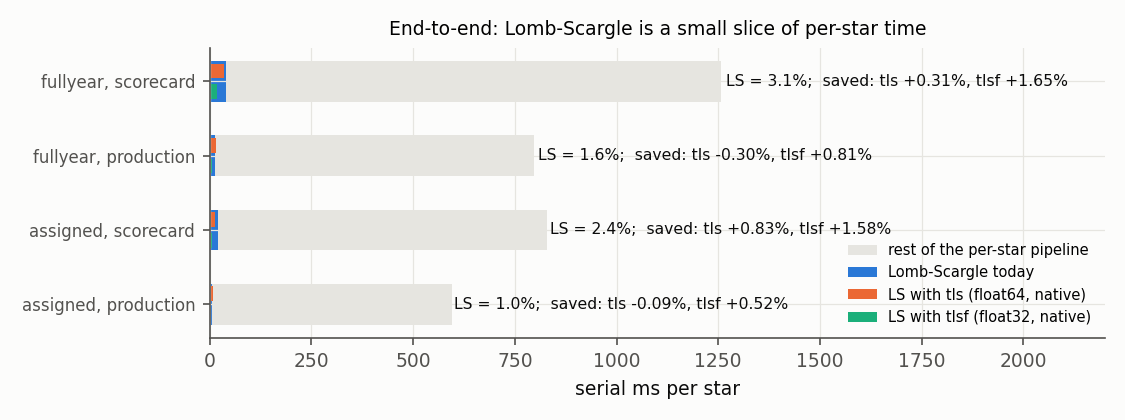

In [10]:
F.fig_end_to_end(); display(Image(F.FIG / 'fig_end_to_end.png'))